State n=1: Energy E = -14.8984
State n=2: Energy E = -3.5586


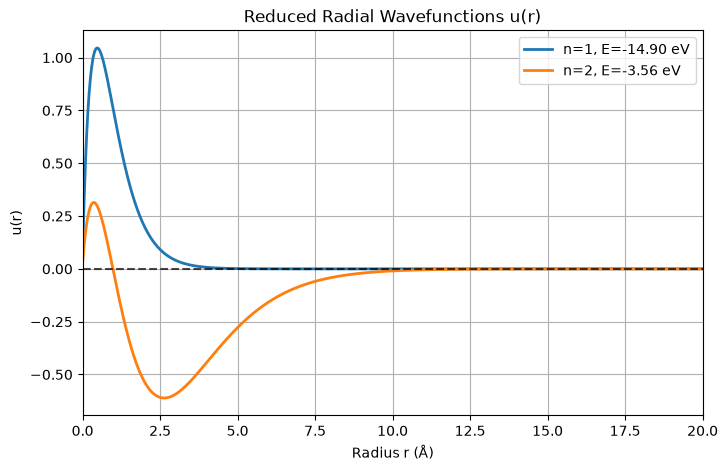

In [5]:
import numpy as np 
import matplotlib.pyplot as plt


hbar_c = 1973.0                 # ħc in (eV·Å)
m_c2 = 0.511e6                  # mc^2 in eV
e = 3.795                       # e in (eV·Å)^(1/2)


hbar2_over_2m = (hbar_c**2) / (2.0 * m_c2)  # ≈ 3.81 eV·Å² 
# here m is the reduced mass of the electron 

N = 1000
r_min = 0.01                    #  in Å
r_max = 20.0                    #  in Å
r = np.linspace(r_min, r_max, N)
h = r[1] - r[0]                 # Step size


V = -(e**2) / r                 # Coulomb potential 

main_diag = 2.0 * np.ones(N)
off_diag = -1.0 * np.ones(N - 1)

K = (hbar2_over_2m / (h**2)) * (np.diag(main_diag) + np.diag(off_diag, 1) + np.diag(off_diag, -1))
H = K + np.diag(V)


energies, wavefunctions = np.linalg.eigh(H)

plt.figure(figsize=(8, 5))

for n in range(0, 2):
    E = energies[n]
    u = wavefunctions[:, n] / np.sqrt(h)
    if u[1] < 0:
        u = -u
    print(f"State n={n+1}: Energy E = {E:.4f}")
    plt.plot(r, u, label=f"n={n+1}, E={E:.2f} eV", linewidth=2)
    

plt.axhline(0, color='black', linestyle='--', alpha=0.7)
plt.title("Reduced Radial Wavefunctions u(r)")
plt.xlabel("Radius r (Å)")
plt.ylabel("u(r)")
plt.xlim(0, 20)
plt.legend()
plt.grid(True)
plt.show()